# GMsFEM для задачи рассеяния в среде с включениями

От ваших CG/DG notebooks — к двум вариантам GMsFEM из Kalachikova et al., *JCAM* 424 (2023), 114977. Всё вычисляется локально в существующем **DOLFINx Complex** окружении.

В этом notebook:

1. Строим `.geo`-геометрию с 24 **заполненными** круглыми включениями и согласованными крупными рёбрами.
2. Решаем тонкосеточную CG1 задачу и строим snapshots, локальные спектры и функции $\chi_p$.
3. Сравниваем Type 1 и Type 2 для $M=1,2,4,6,8,12,16$ на сетках $10\times10$ и $20\times20$.
4. Повторяем опыт с коэффициентами, выбранными по Example 1 статьи.
5. **В самом конце** создаём отдельную более мелкую МКЭ-сетку, решаем эталон и сравниваем поля и интегральные ошибки.

Начните с [README](README.md). Вывод формул: [docs/method.md](docs/method.md). Исходные notebooks сохранены без изменений. Статья: [локальный PDF](../references/10%20GMsFEM%20for%20scattering%20problem.pdf), [DOI](https://doi.org/10.1016/j.cam.2022.114977).

Это воспроизводимая адаптация: координаты взяты из вашей `.geo`, а не оцифрованы заново. Точные авторские сетки не опубликованы, поэтому совпадение всех чисел таблиц не предполагается.

## 1. Окружение и параметры

В JupyterLab выберите ядро **Python (DOLFINx Complex)** и выполните **Run All Cells**. Код не скачивает сетки или установочные скрипты. Здесь используется последовательный SciPy backend; запускать через `mpirun` не нужно.

In [1]:
from pathlib import Path
import sys
import time
import numpy as np
import scipy
import dolfinx
from petsc4py import PETSc
from IPython.display import display, Markdown

%matplotlib inline
import matplotlib.pyplot as plt

# Работает при запуске как из корня проекта, так и из gmsfem/.
REPO = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "gmsfem" / "fem.py").exists()), None)
if REPO is None:
    raise RuntimeError("Откройте notebook внутри multiscale-fem-scattering.")
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))
HERE = REPO / "gmsfem"
assert np.dtype(PETSc.ScalarType).kind == "c", "Нужно ядро DOLFINx Complex"

from gmsfem.geometry import inclusion_circles
from gmsfem.fem import MATERIALS, local_matrices, solve_dirichlet
from gmsfem.offline import build_offline_space, solve_reduced
from gmsfem.metrics import relative_errors
from gmsfem.experiment import run_study, compare_refined, save_study
from gmsfem.plotting import (plot_meshes, plot_basis, plot_fields,
                            plot_convergence, plot_refined_comparison, save_figure)

print(f"DOLFINx {dolfinx.__version__}; SciPy {scipy.__version__}; PETSc {np.dtype(PETSc.ScalarType)}")
print(f"Рабочая папка: {HERE}")

DOLFINx 0.11.0.post0; SciPy 1.17.1; PETSc complex128
Рабочая папка: /workspace/multiscale-fem-scattering/gmsfem


In [2]:
# Исходные коэффициенты notebooks: фон (1,1), включения (alpha,n)=(0.2,10).
CASE = "notebook"
K = 1.0
H_FINE = 0.04                # целевой фоновый шаг; окружности локально сгущены
COARSE_GRIDS = (10, 20)       # число крупных квадратов вдоль каждой оси
MODES = (1, 2, 4, 6, 8, 12, 16)
BASIS_TYPES = (1, 2)
DIRECTION = (1.0, 0.0)
OUTPUT = HERE / "results" / CASE
PAPER_OUTPUT = HERE / "results" / "paper_example1"

# Для первого быстрого знакомства можно поставить COARSE_GRIDS=(4,),
# MODES=(1,2,4), H_FINE=0.10. Все следующие ячейки используют эти переменные.

def show_figure(fig, filename, output=OUTPUT):
    save_figure(fig, output / filename)
    display(fig)
    plt.close(fig)

def show_errors(rows, *, refined=False):
    if refined:
        head = "| Метод | DOF | Re/ref, % | Im/ref, % | Модуль/ref, % | Complex/ref, % |\n|---|---:|---:|---:|---:|---:|"
        body = [f"| {r['label']} | {r['dofs']} | {r['e_real_ref']:.4f} | {r['e_imag_ref']:.4f} | {r['e_abs_ref']:.4f} | {r['e_complex_ref']:.4f} |" for r in rows]
    else:
        head = "| Сетка | Type | M | DOF | Re, % | Im, % | Модуль, % | Complex/ref, % |\n|---|---:|---:|---:|---:|---:|---:|---:|"
        body = [f"| {r['n_coarse']}×{r['n_coarse']} | {r['basis_type']} | {r['modes']} | {r['dofs_coarse']} | {r['e_real_paper']:.4f} | {r['e_imag_paper']:.4f} | {r['e_abs_paper']:.4f} | {r['e_complex_ref']:.4f} |" for r in rows]
    display(Markdown(head + "\n" + "\n".join(body)))

## 2. Постановка и исправление правой части

$A=\alpha I$, $u_i=e^{ikd\cdot x}$, $u=u_i+u_s$. Решаем **рассеянное** поле:

$$
\int_\Omega\alpha\nabla u_s\cdot\nabla\bar v
-k^2\int_\Omega n u_s\bar v
-ik\int_{\partial\Omega}u_s\bar v
=\int_\Omega(1-\alpha)\nabla u_i\cdot\nabla\bar v
+k^2\int_\Omega(n-1)u_i\bar v.
$$

В исходных notebooks `div((1-A)*grad(u_i))*dx` при $A\in DG0$ не содержит распределительного скачка на интерфейсах. Новая **слабая контрастная RHS** сохраняет этот вклад. Её знак дополнительно проверен независимой задачей полного поля с аналитическим Robin forcing.

Глобальный оператор $A_h=K-k^2M_n-ikB$ собирает **DOLFINx**, где $B$ — масса только внешней границы, без множителя $k$. Используется CG1, как в статье; степень CG2 исходного CG notebook и его DG-вариант сюда не переносятся автоматически. Внешний Robin приближает излучение; более мелкая сетка не устраняет ошибку этого условия.

Файлы: [fem.py](fem.py), [geo/scattering.geo](geo/scattering.geo), [geo/reference.geo](geo/reference.geo).

## 3. Основной расчёт

`run_study` выполняет всю цепочку, сохраняя объекты для подробного разбора ниже. Наибольшее число мод строится один раз; меньшие пространства берутся как первые $M$ мод **каждой** окрестности. Для Type 2 при изменении $k$ нужно пересчитать offline-базис.

Одна и та же тонкая сетка согласована с обеими крупными сетками. Генератор `.geo` разрезает окружности и крупные квадраты через `BooleanFragments`, присваивает материалы и кэширует `.msh` с SHA256 исходников. Геометрия находится в `.geo`; Python назначает physical surfaces по проверенным внутренним точкам фрагментов.

In [3]:
started = time.perf_counter()
study = run_study(case=CASE, k=K, h=H_FINE, coarse_grids=COARSE_GRIDS,
                  modes=MODES, basis_types=BASIS_TYPES, direction=DIRECTION,
                  progress=None)
problem, fine = study.problem, study.fine
N_SHOW = min(COARSE_GRIDS)
N_BEST = max(COARSE_GRIDS)
TYPE_SHOW = max(BASIS_TYPES)
M_SHOW = 6 if 6 in MODES else max(MODES)
M_BEST = max(MODES)
print(f"Включений: {len(inclusion_circles())}; площадь области: {problem.areas.sum():.12f}")
print(f"МКЭ: {problem.ndofs:,} DOF; {len(problem.triangles):,} треугольников")
print(f"Невязка МКЭ: {study.fine_diagnostics['relative_residual']:.3e}")
print(f"Совпадение локальной P1 и UFL stiffness: {problem.element_assembly_error:.3e}")
print(f"Расчёт всех Type/H/M: {time.perf_counter()-started:.2f} s")

Info    : Reading '/workspace/multiscale-fem-scattering/gmsfem/meshes/fine_n20_h0p04.msh'...
Info    : 1873 entities
Info    : 17549 nodes
Info    : 35096 elements
Info    : Done reading '/workspace/multiscale-fem-scattering/gmsfem/meshes/fine_n20_h0p04.msh'


Включений: 24; площадь области: 16.000000000000
МКЭ: 17,549 DOF; 34,696 треугольников
Невязка МКЭ: 2.368e-13
Совпадение локальной P1 и UFL stiffness: 6.175e-15
Расчёт всех Type/H/M: 16.65 s


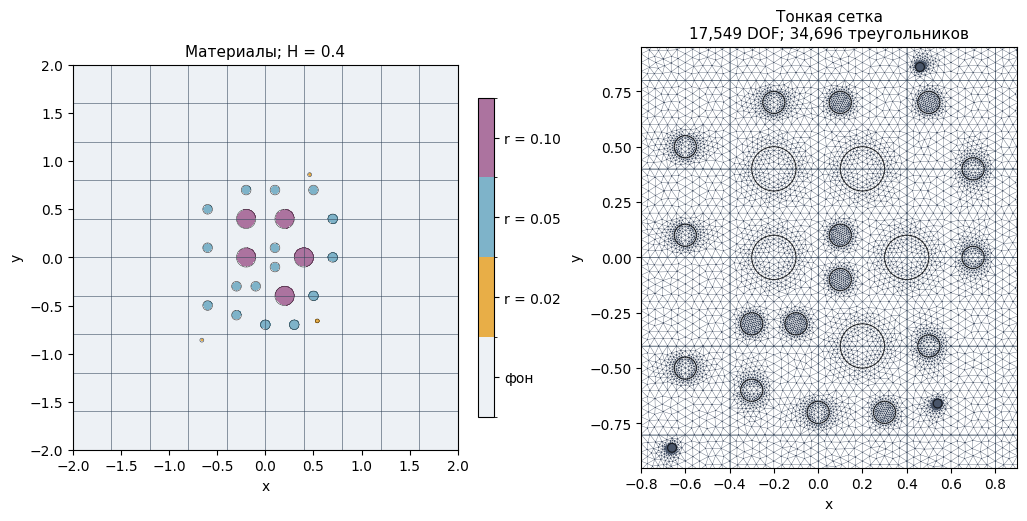

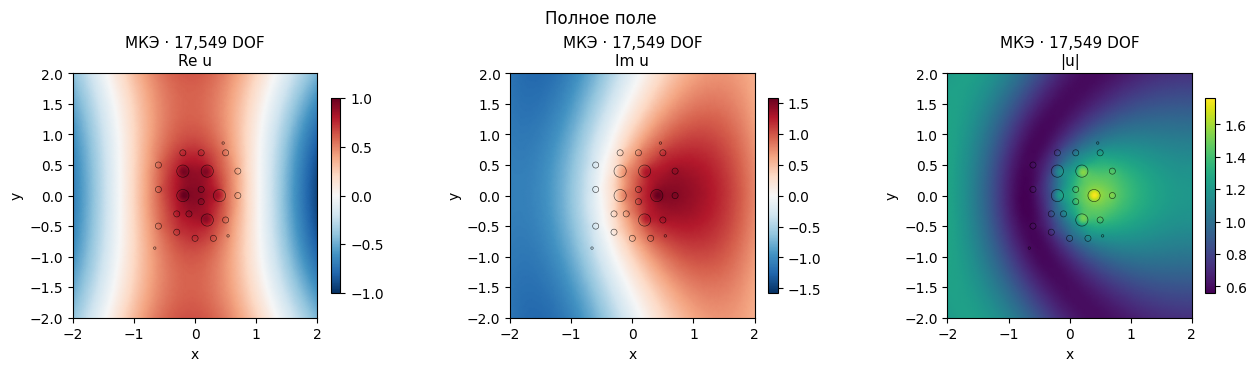

In [4]:
show_figure(plot_meshes(problem, N_SHOW), "meshes.png")
show_figure(plot_fields(problem, fine, [], field="total"), "fine_total.png")

## 4. Что именно решается на одном patch

$\omega_p$ — объединение крупных квадратов вокруг крупной вершины: четыре внутри области, два на стороне, один в углу. На **всей** границе patch берём все тонкие узловые дельты.

Для матрицы граничных продолжений $\Psi$:

$$\Psi_B=I,\qquad \Psi_I=-L_{II}^{-1}L_{IB},\qquad
L=\begin{cases}K&\text{Type 1},\\K-k^2M_n&\text{Type 2}.\end{cases}$$

Локальные матрицы собираются только по элементам patch. Вырезать главную подматрицу глобального stiffness нельзя: на границе остались бы вклады элементов за пределами patch.

Спектральная задача **для обоих типов**:

$$\Psi^T K\Psi z_j=\lambda_j\Psi^T S_\alpha\Psi z_j,
\qquad (S_\alpha)_{ab}=\int_{\omega_p}\alpha\varphi_a\varphi_b.$$

Выбираем **наименьшие** собственные значения. Спектральная масса имеет вес $\alpha$, а не $n$, не $1$ и не иной стандартный GMsFEM-вес. Следующая ячейка независимо раскрывает один из уже рассчитанных patch; она не использует глобальное решение.

In [5]:
from scipy.linalg import eigh
space = study.spaces[N_SHOW, TYPE_SHOW]
preview = space.preview
local = local_matrices(problem, preview["cells"])
L_patch = local.K if TYPE_SHOW == 1 else local.K-K**2*local.Mn
snapshots, snapshot_residual = solve_dirichlet(L_patch, local.boundary, np.eye(len(local.boundary)))
K_snap = snapshots.T @ (local.K @ snapshots)
S_snap = snapshots.T @ (local.Salpha @ snapshots)
number = min(6, max(MODES))
lambdas, _ = eigh((K_snap+K_snap.T)/2, (S_snap+S_snap.T)/2,
                 subset_by_index=(0, number-1))
print(f"Patch вершины {preview['vertex']}: {len(local.dofs)} DOF, {len(local.boundary)} snapshots")
print(f"Внутренняя backward residual: {snapshot_residual:.3e}")
print("Первые λ:", np.round(lambdas, 7))
np.testing.assert_allclose(lambdas, space.eigenvalues[preview['vertex'], :number], rtol=1e-7, atol=1e-9)

Patch вершины 60: 1685 DOF, 104 snapshots
Внутренняя backward residual: 4.605e-18
Первые λ: [ 0.3604515 15.3362875 15.6221333 31.1350524 68.0689802 79.1220642]


## 5. Функции $\chi_p$, моды и глобальный базис

На каждом **крупном квадрате** решаем четыре локальные задачи с тем же $L$ и граничным следом крупной Q1-функции вершины. Соседние ячейки имеют одинаковые следы. Для Type 1 $\sum_p\chi_p=1$; для Type 2 равенство внутри ячейки не обязано выполняться, поэтому деление на сумму не применяется.

$$\phi_{pj}=I_h(\chi_p\,\Psi_p z_j),\qquad P=[\phi_{11},\ldots,\phi_{pM},\ldots].$$

$P$ хранит базис по **столбцам**. $I_h$ — P1 интерполяция произведения узловых значений. Нормировка каждого столбца по L² улучшает обусловленность, сохраняя пространство.

Реализация: [offline.py](offline.py), функции `_partition_functions`, `build_offline_space` и `OfflineSpace.prolongation`.

Type 1: (17549, 1936), nnz=1,164,960, offline=0.643 s
{'chi_dirichlet_residual': 1.4012560868252015e-17, 'chi_interface_defect': 8.326672684688674e-15, 'partition_sum_defect': 3.552713678800501e-15, 'max_snapshot_residual': 1.5615136204795958e-17, 'max_eigen_residual': 1.1571883969924158e-15, 'min_snapshots': 40, 'max_snapshots': 104, 'P_nnz': 1164960}


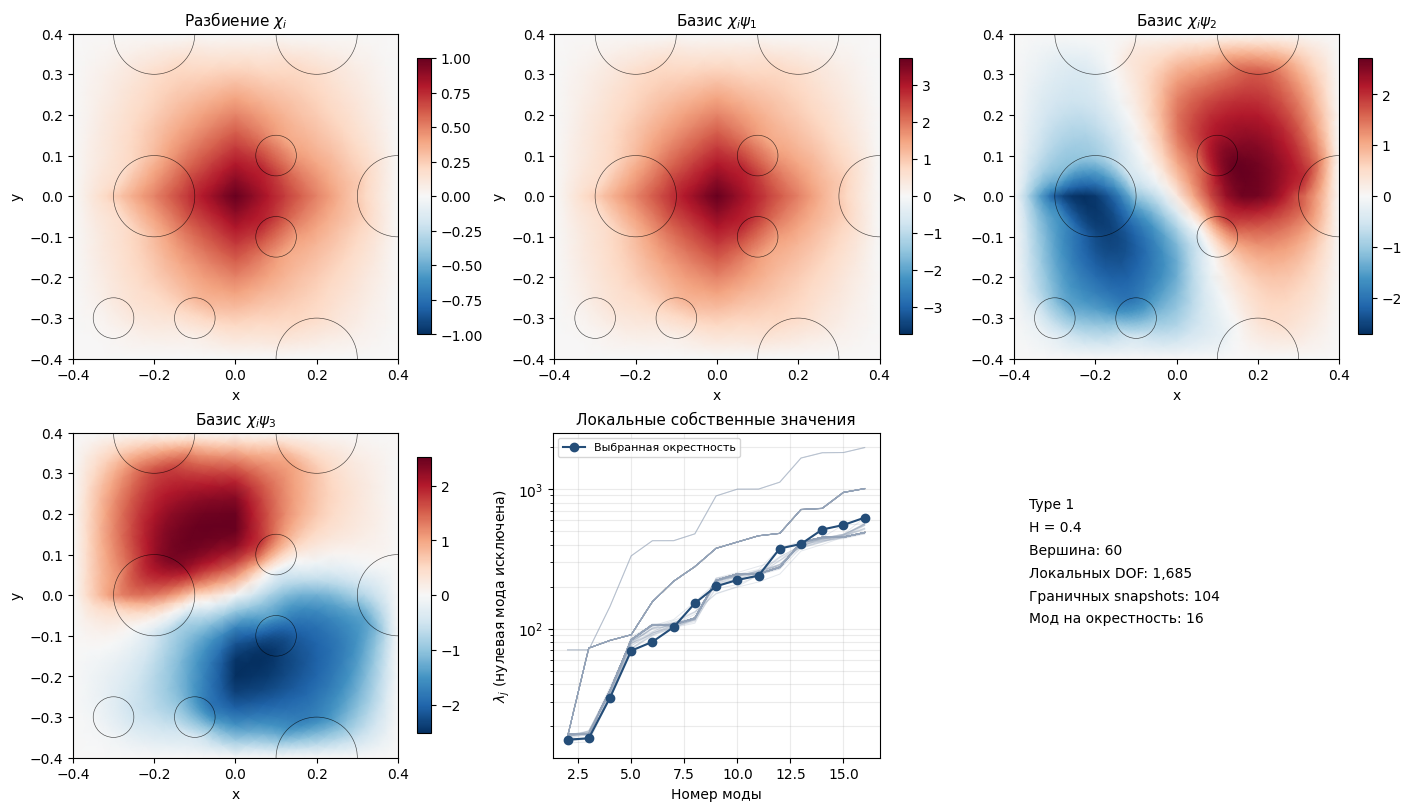

Type 2: (17549, 1936), nnz=1,164,960, offline=0.652 s
{'chi_dirichlet_residual': 1.4247811876831344e-17, 'chi_interface_defect': 8.326672684688674e-15, 'partition_sum_defect': 0.07939977003820253, 'max_snapshot_residual': 1.4016522076478118e-17, 'max_eigen_residual': 1.136546441567937e-15, 'min_snapshots': 40, 'max_snapshots': 104, 'P_nnz': 1164960}


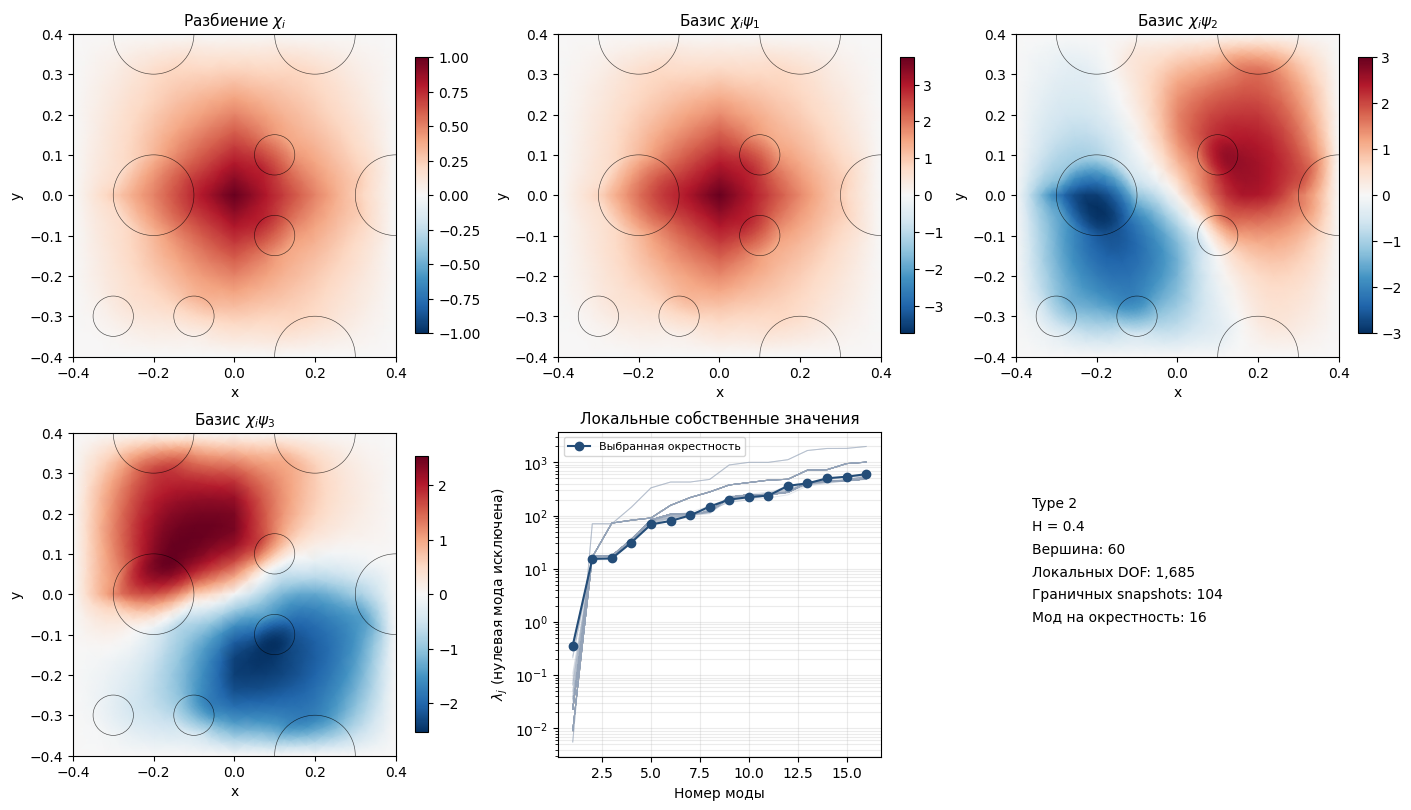

In [6]:
for basis_type in BASIS_TYPES:
    space = study.spaces[N_SHOW, basis_type]
    print(f"Type {basis_type}: {space.P.shape}, nnz={space.P.nnz:,}, offline={space.build_seconds:.3f} s")
    print(space.diagnostics)
    show_figure(plot_basis(problem, space), f"basis_type{basis_type}.png")

## 6. Online-проекция и интегральные ошибки

$$A_H=P^H A_hP,\qquad F_H=P^HF_h,\qquad A_HU_H=F_H,\qquad U_{ms}=PU_H.$$

Здесь $H$ у $P^H$ означает сопряжённое транспонирование. Число неизвестных $N_H=(N_{coarse}+1)^2M$. Глобальное тонкое решение не участвует в построении $P$ и используется только для сравнения.

Основная таблица относится к **полному полю**. Для Re, Im и модуля показан знаменатель из формулы статьи:

$$e_{paper}(q)=100\frac{\|q_{ms}-q_h\|_{L^2}}{\|q_{ms}\|_{L^2}}.$$

Последний столбец — комплексная ошибка с обычным reference-знаменателем $\|u_h\|$. CSV содержит оба соглашения и отдельно рассеянное поле. Квадратура семиточечная; падающая волна вычисляется аналитически. Для модуля интегрируется $|u_{ms}|-|u_h|$, а не P1-интерполянт узловых модулей.

{'dofs_coarse': 2646, 'dofs_fine': 17549, 'compression': 6.632275132275132, 'projection_seconds': 0.03647895800168044, 'solve_seconds': 0.21653245899869944, 'galerkin_residual': 3.948190528325478e-14}
Pure reduction, complex/ref (%): 0.5522145863674175


| Сетка | Type | M | DOF | Re, % | Im, % | Модуль, % | Complex/ref, % |
|---|---:|---:|---:|---:|---:|---:|---:|
| 10×10 | 1 | 1 | 121 | 8.2274 | 4.2710 | 3.2533 | 5.4602 |
| 10×10 | 1 | 2 | 242 | 6.6319 | 3.4369 | 2.6740 | 4.3908 |
| 10×10 | 1 | 4 | 484 | 4.2054 | 1.9301 | 1.6639 | 2.6269 |
| 10×10 | 1 | 6 | 726 | 3.8411 | 1.7248 | 1.5279 | 2.3767 |
| 10×10 | 1 | 8 | 968 | 3.6511 | 1.6305 | 1.4490 | 2.2530 |
| 10×10 | 1 | 12 | 1452 | 3.3555 | 1.4971 | 1.3389 | 2.0683 |
| 10×10 | 1 | 16 | 1936 | 1.9595 | 0.8676 | 0.7764 | 1.1996 |
| 10×10 | 2 | 1 | 121 | 4.0139 | 2.5160 | 1.9538 | 2.9242 |
| 10×10 | 2 | 2 | 242 | 3.1540 | 2.1491 | 1.7143 | 2.4177 |
| 10×10 | 2 | 4 | 484 | 1.8697 | 1.2387 | 1.0067 | 1.4057 |
| 10×10 | 2 | 6 | 726 | 1.8386 | 1.1687 | 0.9547 | 1.3483 |
| 10×10 | 2 | 8 | 968 | 1.7811 | 1.1160 | 0.9098 | 1.2948 |
| 10×10 | 2 | 12 | 1452 | 1.5895 | 0.9676 | 0.7936 | 1.1358 |
| 10×10 | 2 | 16 | 1936 | 0.7617 | 0.4112 | 0.3699 | 0.5092 |
| 20×20 | 1 | 1 | 441 | 4.9530 | 2.5332 | 1.9125 | 3.2426 |
| 20×20 | 1 | 2 | 882 | 4.4431 | 2.1611 | 1.7061 | 2.8431 |
| 20×20 | 1 | 4 | 1764 | 3.1757 | 1.4323 | 1.2593 | 1.9649 |
| 20×20 | 1 | 6 | 2646 | 2.9107 | 1.3122 | 1.1676 | 1.7999 |
| 20×20 | 1 | 8 | 3528 | 1.3629 | 0.6133 | 0.5441 | 0.8387 |
| 20×20 | 1 | 12 | 5292 | 1.2033 | 0.5427 | 0.4861 | 0.7409 |
| 20×20 | 1 | 16 | 7056 | 0.9677 | 0.4406 | 0.3971 | 0.5979 |
| 20×20 | 2 | 1 | 441 | 1.9886 | 1.2720 | 0.9056 | 1.4589 |
| 20×20 | 2 | 2 | 882 | 1.5290 | 0.8768 | 0.6764 | 1.0548 |
| 20×20 | 2 | 4 | 1764 | 1.0316 | 0.4336 | 0.4102 | 0.6159 |
| 20×20 | 2 | 6 | 2646 | 0.9487 | 0.3727 | 0.3690 | 0.5522 |
| 20×20 | 2 | 8 | 3528 | 0.4920 | 0.2238 | 0.2114 | 0.3033 |
| 20×20 | 2 | 12 | 5292 | 0.4186 | 0.1522 | 0.1655 | 0.2373 |
| 20×20 | 2 | 16 | 7056 | 0.3214 | 0.0895 | 0.1192 | 0.1696 |

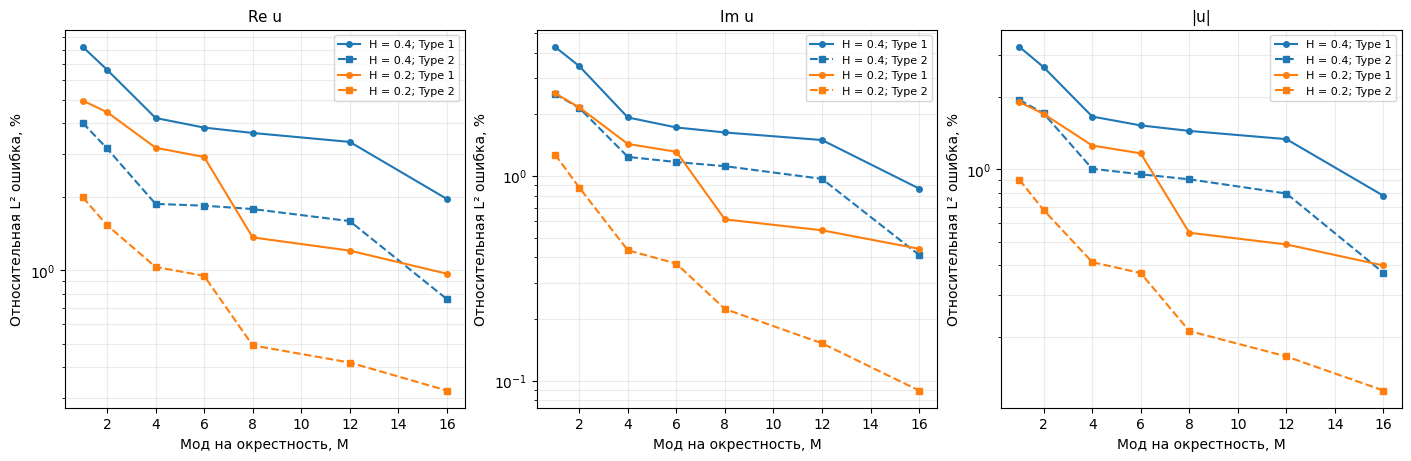

In [7]:
# Один явный online solve для чтения алгоритма; те же данные уже есть в study.
space = study.spaces[N_BEST, TYPE_SHOW]
u_ms, online = solve_reduced(problem, space, M_SHOW)
print(online)
print("Pure reduction, complex/ref (%):", relative_errors(problem, u_ms, fine)["e_complex_ref"])
show_errors(study.rows)
show_figure(plot_convergence(study.rows), "convergence.png")

## 7. Сравнение полей: тонкий МКЭ и две крупные сетки

Как в сравнительных рисунках статьи, первая строка — тонкий МКЭ, следующие — GMsFEM на двух крупных сетках с одинаковым числом мод. В каждом столбце используются **одинаковые шкалы**. Сначала показано согласованное полное поле; затем отдельно рассеянное.

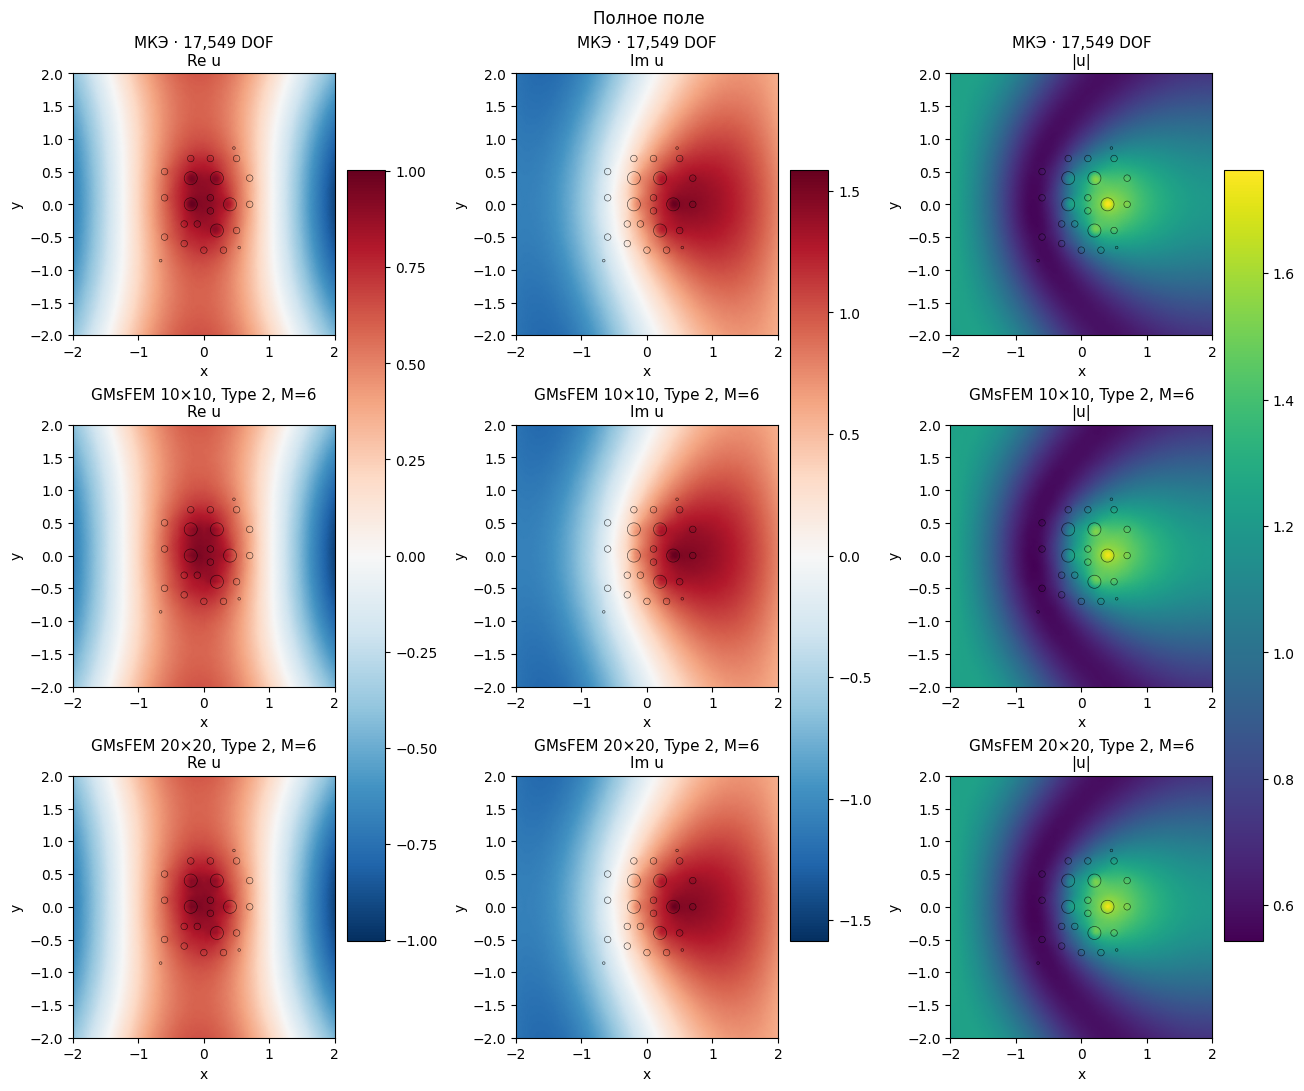

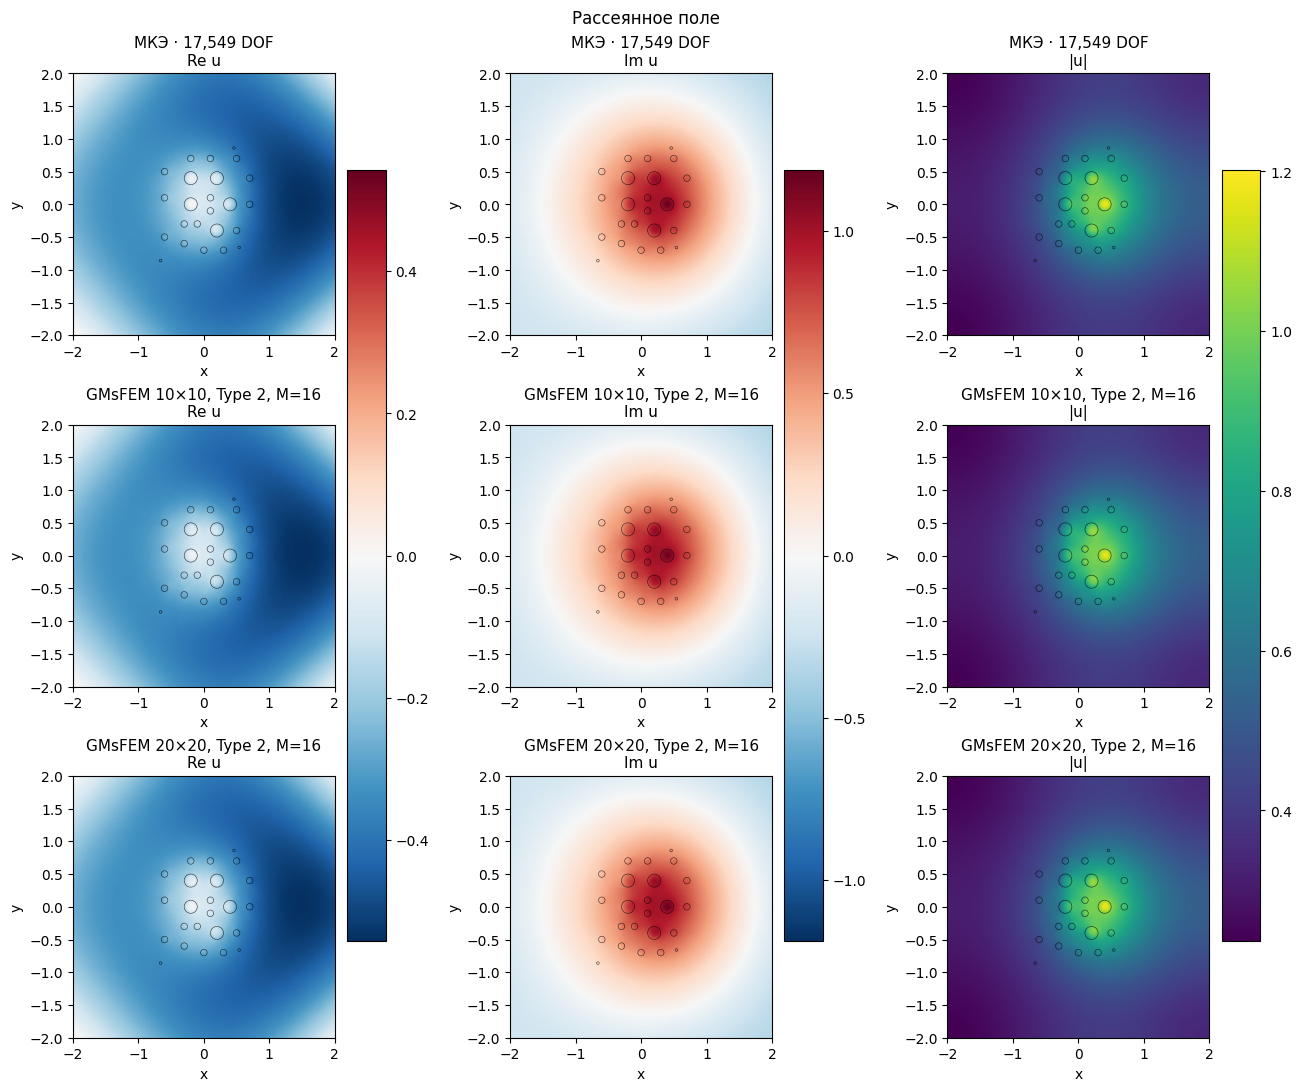

In [8]:
approximations = [(f"GMsFEM {nc}×{nc}, Type {TYPE_SHOW}, M={M_SHOW}",
                   study.solutions[nc, TYPE_SHOW, M_SHOW]) for nc in COARSE_GRIDS]
show_figure(plot_fields(problem, fine, approximations, field="total"), "fields_total.png")
best_approximations = [(f"GMsFEM {nc}×{nc}, Type {TYPE_SHOW}, M={M_BEST}",
                       study.solutions[nc, TYPE_SHOW, M_BEST]) for nc in COARSE_GRIDS]
show_figure(plot_fields(problem, fine, best_approximations, field="scattered"), "fields_scattered.png")

## 8. Коэффициенты Example 1 и оформление как в исходном DG notebook

Для отдельного опыта выбираем материалы по Fig. 7: крупные голубые включения $(\alpha,n)=(3,0.8)$, средние $(5,0.4)$, мелкие красные $(10,0.2)$. Координаты и радиусы остаются из проекта. Принято $A=\alpha I$; эта связь не выписана явно в численной части статьи.

В Fig. 8 есть неоднозначность: диапазоны Re/Im и Abs не могут относиться к одному полю. Исходный DG notebook проекта выводит $\operatorname{Re}u_s$, $\operatorname{Im}u_s$, $|u_i+u_s|$. Ниже воспроизводится **именно эта явно подписанная смешанная тройка** (`paper_mixed`). Это правдоподобная интерпретация картинки статьи, а не подтверждённая авторами конвенция. Основные CSV-метрики при этом остаются разделёнными на total/scattered.

Info    : Reading '/workspace/multiscale-fem-scattering/gmsfem/meshes/fine_n20_h0p04.msh'...
Info    : 1873 entities
Info    : 17549 nodes
Info    : 35096 elements
Info    : Done reading '/workspace/multiscale-fem-scattering/gmsfem/meshes/fine_n20_h0p04.msh'


Материалы Fig.7; DOF тонкого МКЭ: 17,549


| Сетка | Type | M | DOF | Re, % | Im, % | Модуль, % | Complex/ref, % |
|---|---:|---:|---:|---:|---:|---:|---:|
| 10×10 | 1 | 1 | 121 | 1.0158 | 0.9048 | 0.5215 | 0.9493 |
| 10×10 | 1 | 2 | 242 | 0.9502 | 0.8451 | 0.4783 | 0.8877 |
| 10×10 | 1 | 4 | 484 | 0.2456 | 0.3689 | 0.1419 | 0.3239 |
| 10×10 | 1 | 6 | 726 | 0.1717 | 0.3181 | 0.0786 | 0.2678 |
| 10×10 | 1 | 8 | 968 | 0.1478 | 0.3032 | 0.0587 | 0.2512 |
| 10×10 | 1 | 12 | 1452 | 0.1300 | 0.2736 | 0.0431 | 0.2259 |
| 10×10 | 1 | 16 | 1936 | 0.1104 | 0.2410 | 0.0309 | 0.1980 |
| 10×10 | 2 | 1 | 121 | 1.0191 | 0.9046 | 0.5211 | 0.9507 |
| 10×10 | 2 | 2 | 242 | 0.9530 | 0.8433 | 0.4766 | 0.8880 |
| 10×10 | 2 | 4 | 484 | 0.2442 | 0.3718 | 0.1435 | 0.3254 |
| 10×10 | 2 | 6 | 726 | 0.1695 | 0.3166 | 0.0762 | 0.2661 |
| 10×10 | 2 | 8 | 968 | 0.1468 | 0.3024 | 0.0572 | 0.2504 |
| 10×10 | 2 | 12 | 1452 | 0.1298 | 0.2734 | 0.0428 | 0.2257 |
| 10×10 | 2 | 16 | 1936 | 0.1109 | 0.2410 | 0.0315 | 0.1981 |
| 20×20 | 1 | 1 | 441 | 0.9583 | 0.8698 | 0.4791 | 0.9049 |
| 20×20 | 1 | 2 | 882 | 0.1993 | 0.2958 | 0.0702 | 0.2605 |
| 20×20 | 1 | 4 | 1764 | 0.1176 | 0.2472 | 0.0432 | 0.2041 |
| 20×20 | 1 | 6 | 2646 | 0.0951 | 0.2047 | 0.0299 | 0.1685 |
| 20×20 | 1 | 8 | 3528 | 0.0844 | 0.1797 | 0.0268 | 0.1481 |
| 20×20 | 1 | 12 | 5292 | 0.0621 | 0.1349 | 0.0135 | 0.1109 |
| 20×20 | 1 | 16 | 7056 | 0.0512 | 0.1151 | 0.0088 | 0.0942 |
| 20×20 | 2 | 1 | 441 | 0.9508 | 0.8643 | 0.4747 | 0.8986 |
| 20×20 | 2 | 2 | 882 | 0.1970 | 0.2963 | 0.0695 | 0.2600 |
| 20×20 | 2 | 4 | 1764 | 0.1169 | 0.2472 | 0.0431 | 0.2040 |
| 20×20 | 2 | 6 | 2646 | 0.0948 | 0.2047 | 0.0298 | 0.1684 |
| 20×20 | 2 | 8 | 3528 | 0.0836 | 0.1795 | 0.0264 | 0.1478 |
| 20×20 | 2 | 12 | 5292 | 0.0621 | 0.1349 | 0.0135 | 0.1109 |
| 20×20 | 2 | 16 | 7056 | 0.0512 | 0.1151 | 0.0088 | 0.0942 |

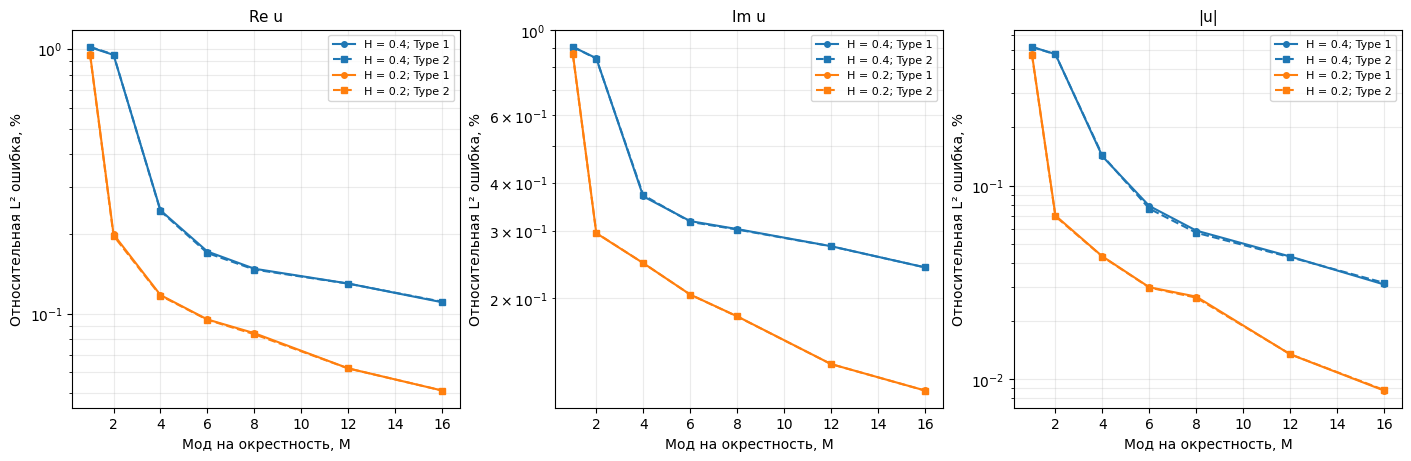

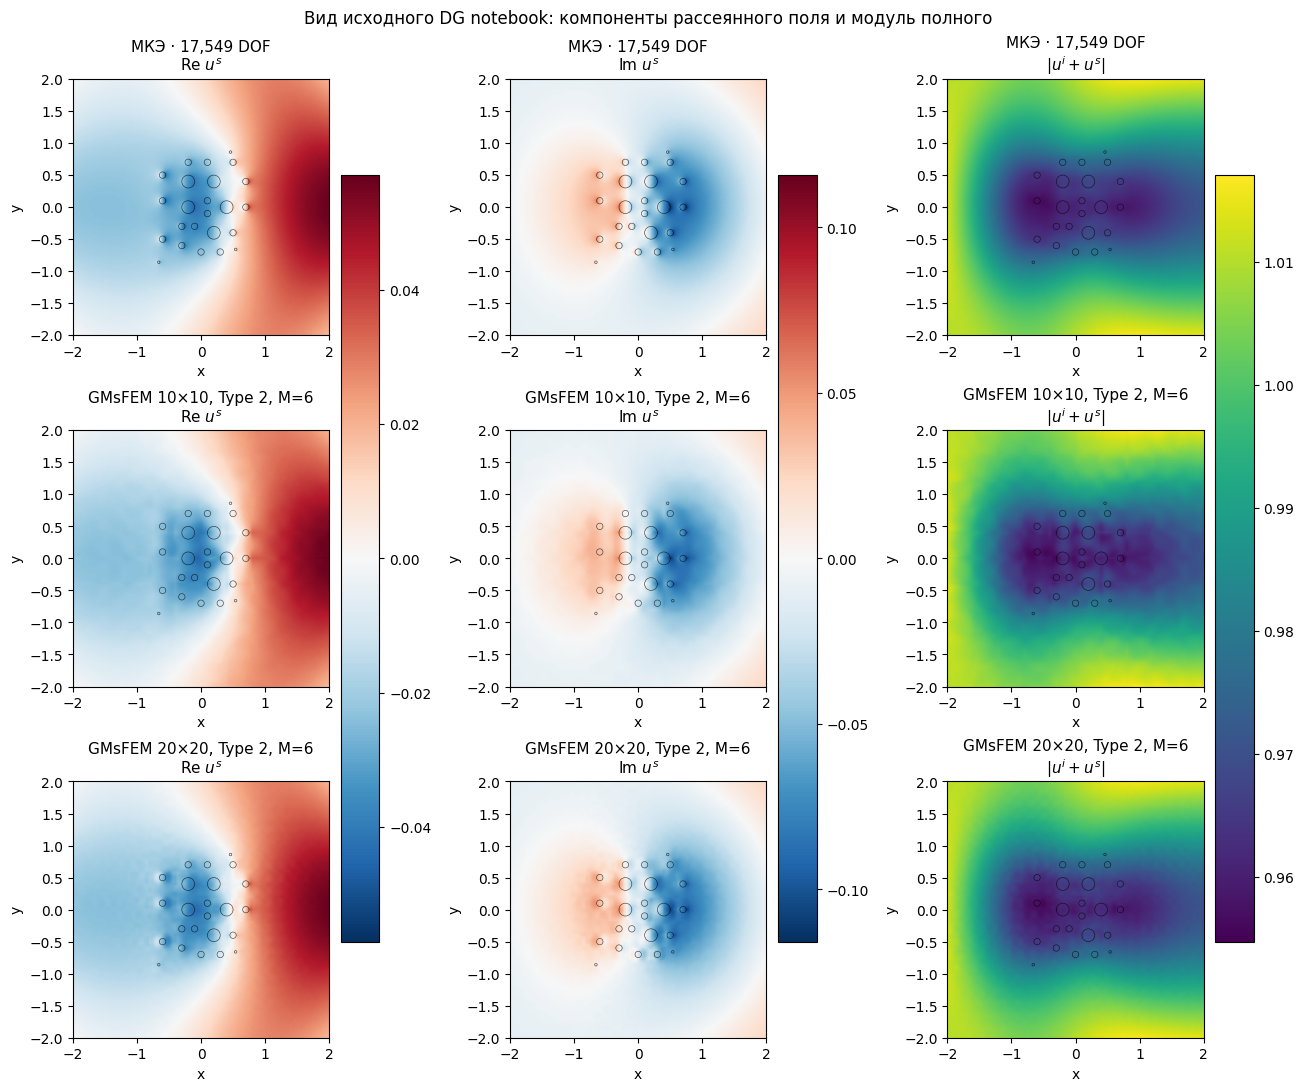

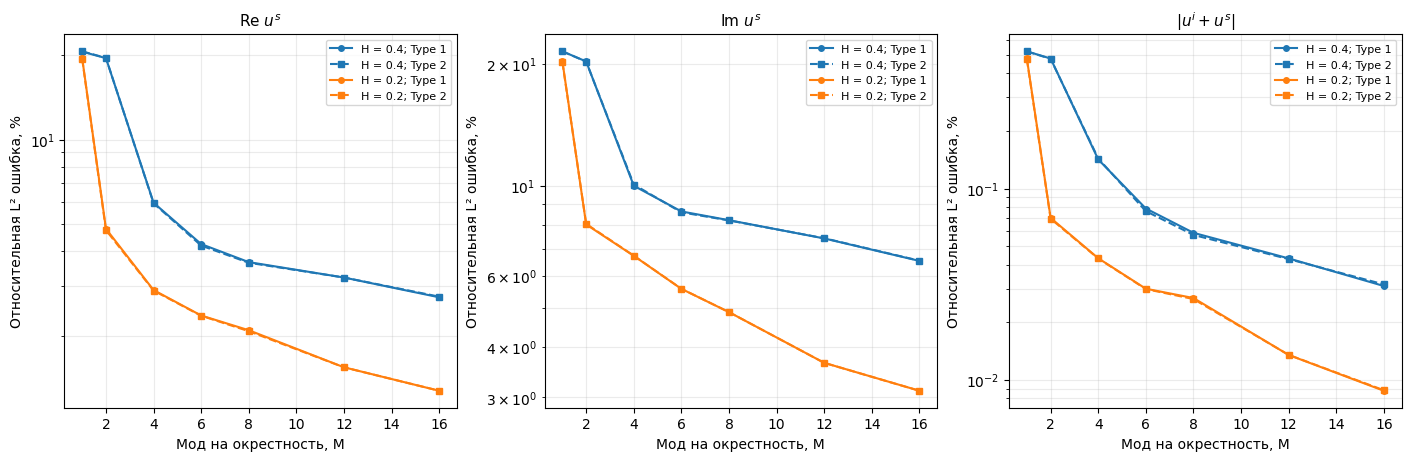

In [9]:
paper_study = run_study(case="paper_example1", k=K, h=H_FINE,
                        coarse_grids=COARSE_GRIDS, modes=MODES,
                        basis_types=BASIS_TYPES, direction=DIRECTION, progress=None)
print(f"Материалы Fig.7; DOF тонкого МКЭ: {paper_study.problem.ndofs:,}")
show_errors(paper_study.rows)
show_figure(plot_convergence(paper_study.rows), "convergence.png", PAPER_OUTPUT)
paper_approximations = [(f"GMsFEM {nc}×{nc}, Type {TYPE_SHOW}, M={M_SHOW}",
                         paper_study.solutions[nc, TYPE_SHOW, M_SHOW]) for nc in COARSE_GRIDS]
show_figure(plot_fields(paper_study.problem, paper_study.fine, paper_approximations,
                       field="paper_mixed"), "fields_dg_style.png", PAPER_OUTPUT)
# Отдельная таблица смешанной конвенции, не меняющая исходные CSV total/scattered.
mixed_rows = [dict(r, field="paper_mixed", e_real_paper=r["scattered_e_real_paper"],
                  e_imag_paper=r["scattered_e_imag_paper"]) for r in paper_study.rows]
show_figure(plot_convergence(mixed_rows), "convergence_dg_style.png", PAPER_OUTPUT)

## 9. Как изменять опыт и читать исходники

Путь по коду: `geometry.py → fem.py → offline.py → metrics.py → experiment.py`. Начните с `solve_dirichlet`: одна факторизация решает все граничные дельты; затем прочитайте `build_offline_space` и `solve_reduced`. Формулы и тонкости собраны в [методической документации](docs/method.md).

- Другой $k$: измените `K` и выполните notebook заново. Для серии используйте CLI `--k 0.1`, `0.5`, `1`, `2`, как в статье.
- Другой материал: `CASE="paper_example2"` задаёт $(10,0.2)$ во всех включениях. Полный список — `fem.MATERIALS`.
- Более тонкая сетка: `H_FINE=0.015` даёт порядок $10^5$ DOF, ближе к статье. Локальное сгущение окружностей сохраняется.
- При слишком большом $M$ относительно числа локальных snapshots или числа fine DOF код выдаст ошибку. Сингулярные локальные Type 2 задачи возможны вблизи Dirichlet-резонанса; метод не маскирует их регуляризацией.

Проверки: `docker compose exec -T dolfinx-complex python3 -m unittest discover -s gmsfem/tests -v`. Проверяется физическая RHS, исчезновение рассеяния без контраста, геометрия, локальная сборка, спектры, галеркинская невязка, обогащение базиса, интегральные нормы и межсеточный перенос.

## 10. Финальный этап: отдельная эталонная сетка МКЭ

Теперь генерируется **новая** сетка с теми же CAD-включениями и целевым шагом $h/2$. На ней независимо решается обычный CG1 МКЭ. Решения исходной сетки интерполируются в **точки квадратуры эталонной сетки** по содержащим треугольникам, без nearest-neighbour переноса.

Сравниваем полное поле. В этой финальной таблице все относительные ошибки имеют знаменатель **refined FEM**, чтобы они были сопоставимы между строками. Ошибка `МКЭ h` оценивает влияние тонкой дискретизации; строки GMsFEM содержат также ошибку редукции. Обе сетки аппроксимируют окружности многоугольниками; даже refined FEM является численным эталоном, а не аналитически точным решением. Ошибка внешнего Robin здесь общая для обоих методов.

Info    : Reading '/workspace/multiscale-fem-scattering/gmsfem/meshes/reference_n20_h0p04.msh'...
Info    : 1873 entities
Info    : 53246 nodes
Info    : 106490 elements
Info    : Done reading '/workspace/multiscale-fem-scattering/gmsfem/meshes/reference_n20_h0p04.msh'


Основной МКЭ: 17,549 DOF; эталон h/2: 53,246 DOF
Невязка эталона: 4.181e-13


| Метод | DOF | Re/ref, % | Im/ref, % | Модуль/ref, % | Complex/ref, % |
|---|---:|---:|---:|---:|---:|
| МКЭ h | 17549 | 0.0693 | 0.0389 | 0.0272 | 0.0472 |
| GMsFEM 10×10, Type 1, M=16 | 1936 | 2.0374 | 0.8983 | 0.7957 | 1.2390 |
| GMsFEM 10×10, Type 2, M=16 | 1936 | 0.7563 | 0.4138 | 0.3734 | 0.5084 |
| GMsFEM 20×20, Type 1, M=16 | 7056 | 1.0304 | 0.4724 | 0.4162 | 0.6369 |
| GMsFEM 20×20, Type 2, M=16 | 7056 | 0.3285 | 0.1017 | 0.1279 | 0.1778 |

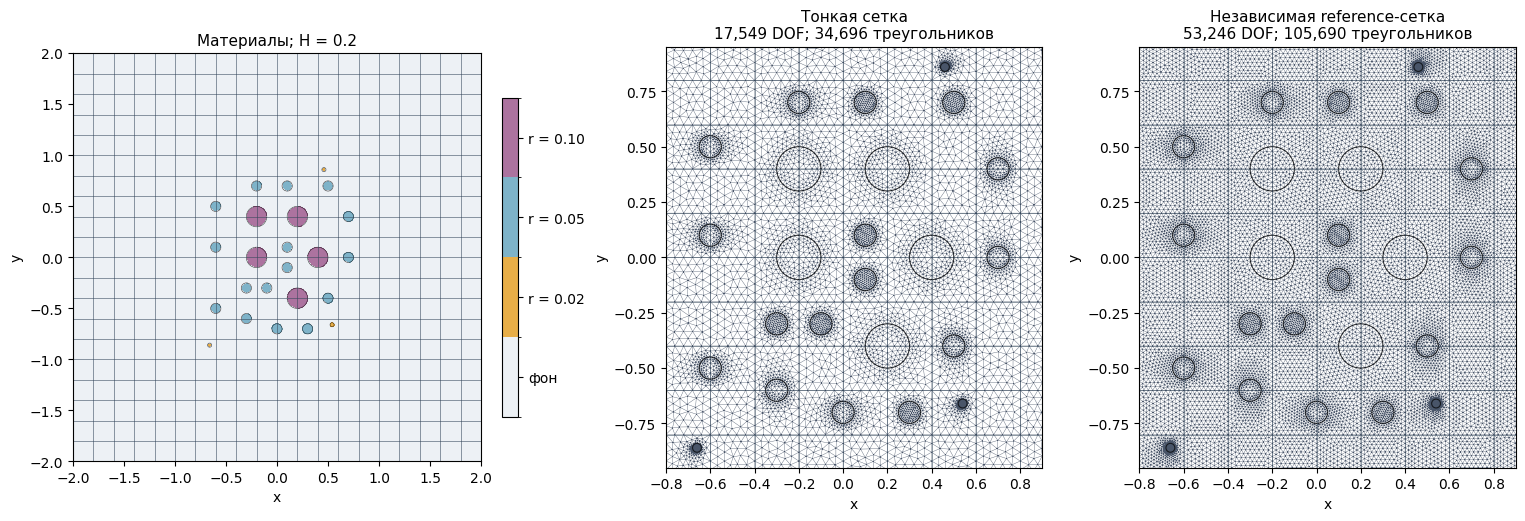

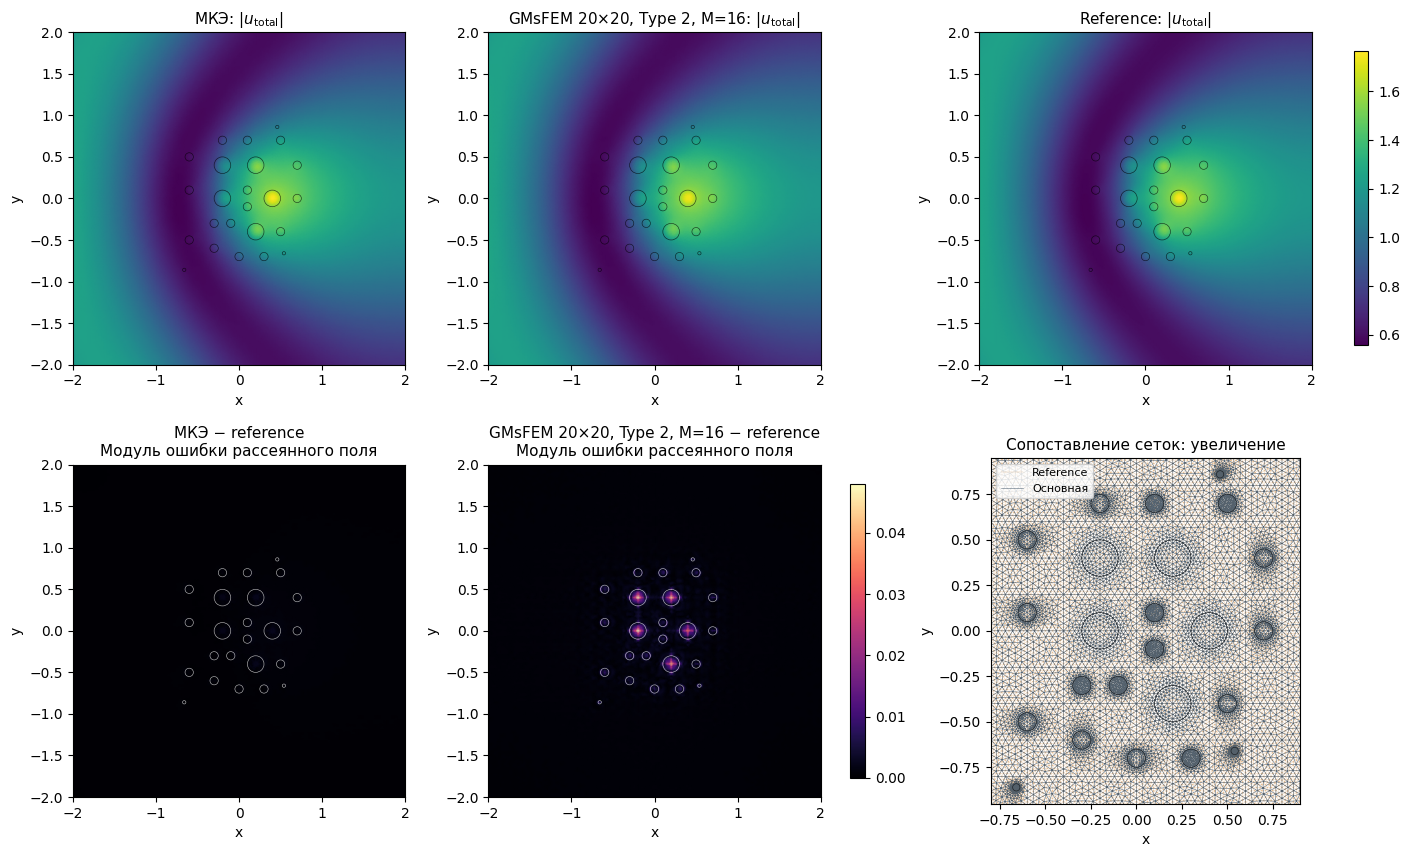

Info    : Reading '/workspace/multiscale-fem-scattering/gmsfem/meshes/reference_n20_h0p04.msh'...
Info    : 1873 entities
Info    : 53246 nodes
Info    : 106490 elements
Info    : Done reading '/workspace/multiscale-fem-scattering/gmsfem/meshes/reference_n20_h0p04.msh'


**Тот же независимый МКЭ-контроль для материалов Example 1:**

| Метод | DOF | Re/ref, % | Im/ref, % | Модуль/ref, % | Complex/ref, % |
|---|---:|---:|---:|---:|---:|
| МКЭ h | 17549 | 0.0139 | 0.0125 | 0.0071 | 0.0131 |
| GMsFEM 10×10, Type 1, M=16 | 1936 | 0.1123 | 0.2425 | 0.0324 | 0.1995 |
| GMsFEM 10×10, Type 2, M=16 | 1936 | 0.1127 | 0.2423 | 0.0336 | 0.1995 |
| GMsFEM 20×20, Type 1, M=16 | 7056 | 0.0535 | 0.1163 | 0.0116 | 0.0956 |
| GMsFEM 20×20, Type 2, M=16 | 7056 | 0.0534 | 0.1162 | 0.0117 | 0.0955 |

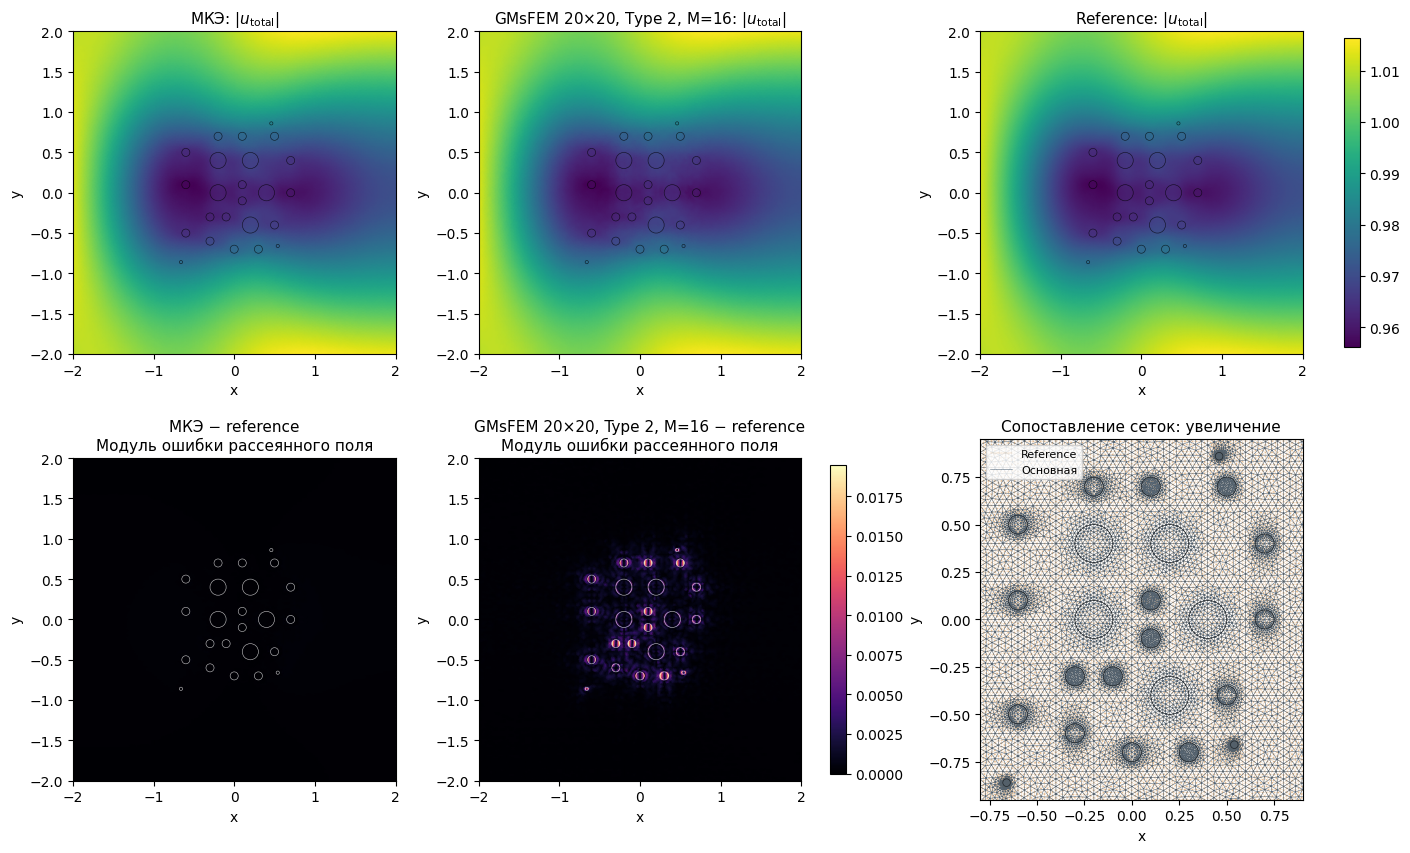

In [10]:
reference = compare_refined(study, progress=None)
print(f"Основной МКЭ: {problem.ndofs:,} DOF; эталон h/2: {reference.problem.ndofs:,} DOF")
print(f"Невязка эталона: {reference.diagnostics['relative_residual']:.3e}")
show_errors(reference.rows, refined=True)
show_figure(plot_meshes(problem, N_BEST, reference.problem), "meshes.png")
show_figure(plot_refined_comparison(problem, fine,
    study.solutions[N_BEST, TYPE_SHOW, M_BEST], reference.problem, reference.fine,
    f"GMsFEM {N_BEST}×{N_BEST}, Type {TYPE_SHOW}, M={M_BEST}"), "reference_comparison.png")

paper_reference = compare_refined(paper_study, progress=None)
display(Markdown("**Тот же независимый МКЭ-контроль для материалов Example 1:**"))
show_errors(paper_reference.rows, refined=True)
show_figure(plot_refined_comparison(paper_study.problem, paper_study.fine,
    paper_study.solutions[N_BEST, TYPE_SHOW, M_BEST], paper_reference.problem, paper_reference.fine,
    f"GMsFEM {N_BEST}×{N_BEST}, Type {TYPE_SHOW}, M={M_BEST}"), "reference_comparison.png", PAPER_OUTPUT)

In [11]:
# Таблицы, поля и provenance относятся к реально выполненным вычислениям.
save_study(study, OUTPUT, reference)
save_study(paper_study, PAPER_OUTPUT, paper_reference)
best = next(r for r in study.rows if (r["n_coarse"],r["basis_type"],r["modes"]) == (N_BEST,TYPE_SHOW,M_BEST))
final = next(r for r in reference.rows if (r["n_coarse"],r["basis_type"],r["modes"]) == (N_BEST,TYPE_SHOW,M_BEST))
display(Markdown(
    f"**Результат:** Type {TYPE_SHOW}, {N_BEST}×{N_BEST}, M={M_BEST}: "
    f"{best['dofs_coarse']:,} неизвестных вместо {problem.ndofs:,}. "
    f"Ошибка модуля к общему fine FEM: **{best['e_abs_paper']:.4f}%**; "
    f"к независимому refined FEM: **{final['e_abs_ref']:.4f}%**. "
    f"Комплексная ошибка к refined FEM: **{final['e_complex_ref']:.4f}%**.\n\n"
    "Сохранено: [отчёт основного опыта](results/notebook/report.md), "
    "[отчёт с материалами статьи](results/paper_example1/report.md), "
    "CSV с обоими соглашениями ошибок, NPZ с полями/спектрами и PNG. "
    "`summary.json` содержит параметры, версии библиотек, SHA256 кода и невязки."))

**Результат:** Type 2, 20×20, M=16: 7,056 неизвестных вместо 17,549. Ошибка модуля к общему fine FEM: **0.1192%**; к независимому refined FEM: **0.1279%**. Комплексная ошибка к refined FEM: **0.1778%**.

Сохранено: [отчёт основного опыта](results/notebook/report.md), [отчёт с материалами статьи](results/paper_example1/report.md), CSV с обоими соглашениями ошибок, NPZ с полями/спектрами и PNG. `summary.json` содержит параметры, версии библиотек, SHA256 кода и невязки.